In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

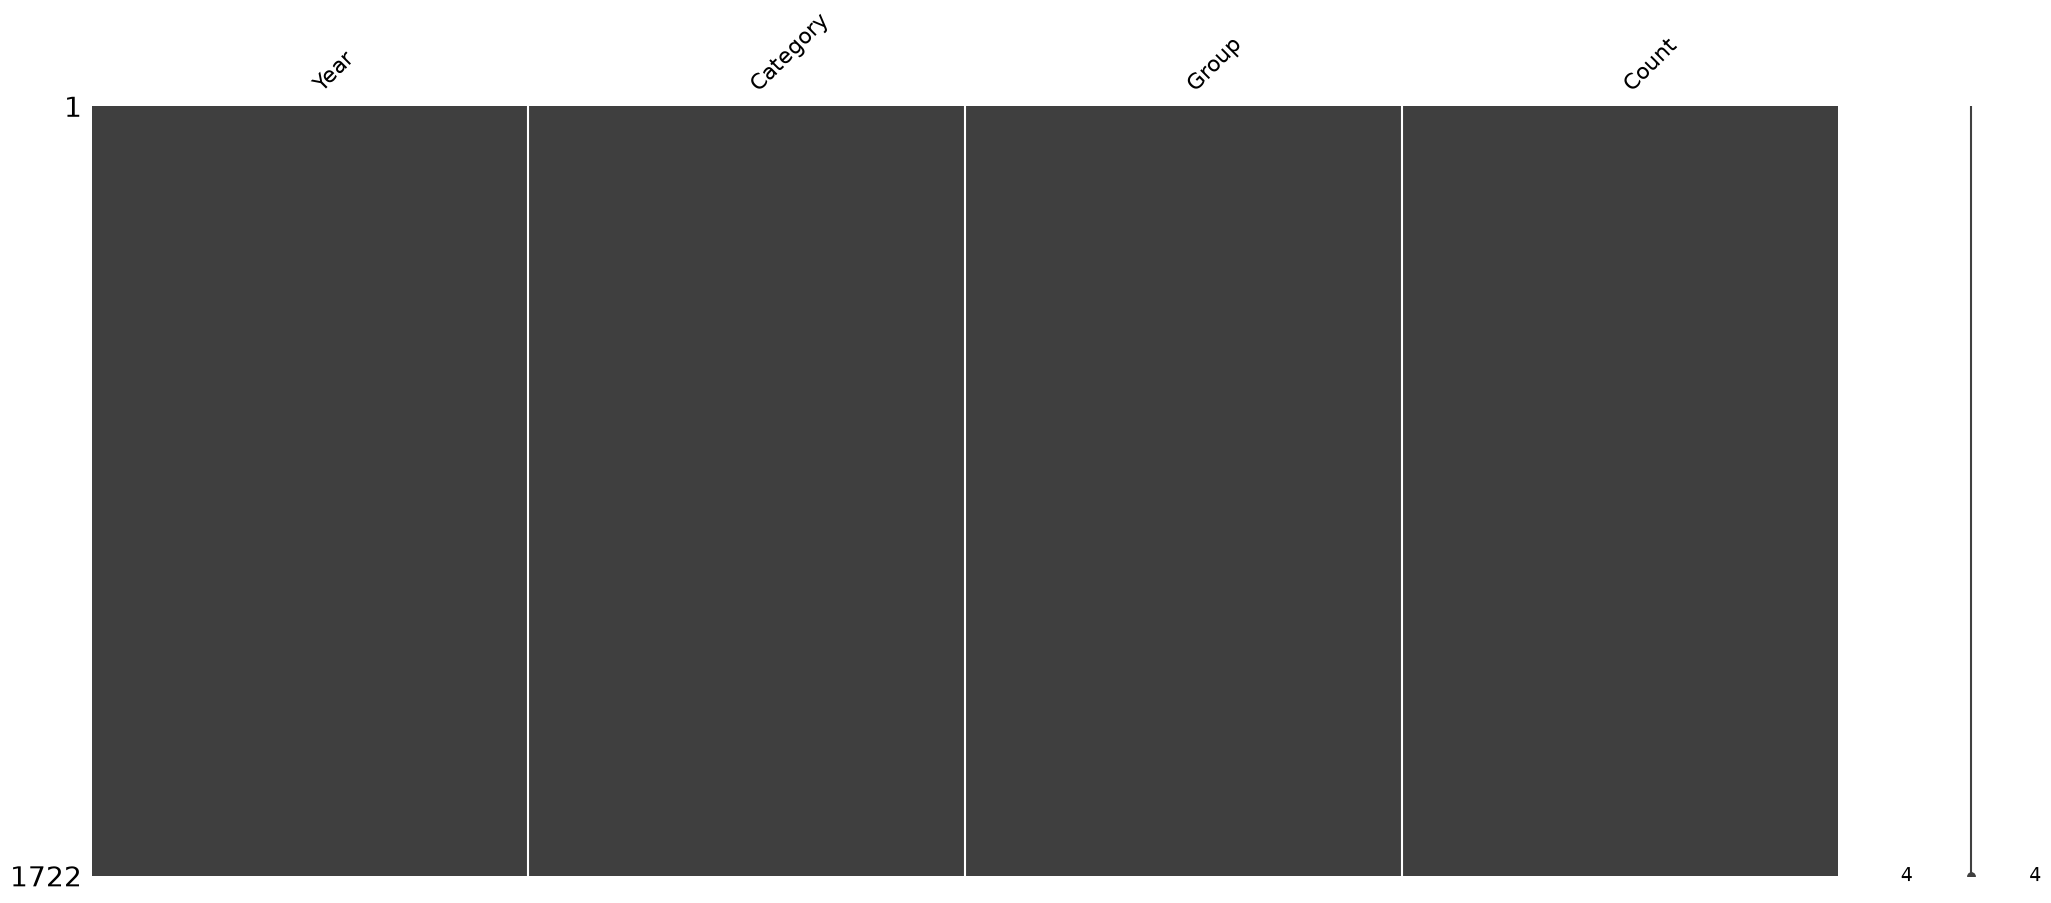

In [3]:
persons_living_with_hiv_aids = pd.read_csv("persons-living-with-hiv-aids.csv")
msno.matrix(persons_living_with_hiv_aids)
plt.show()

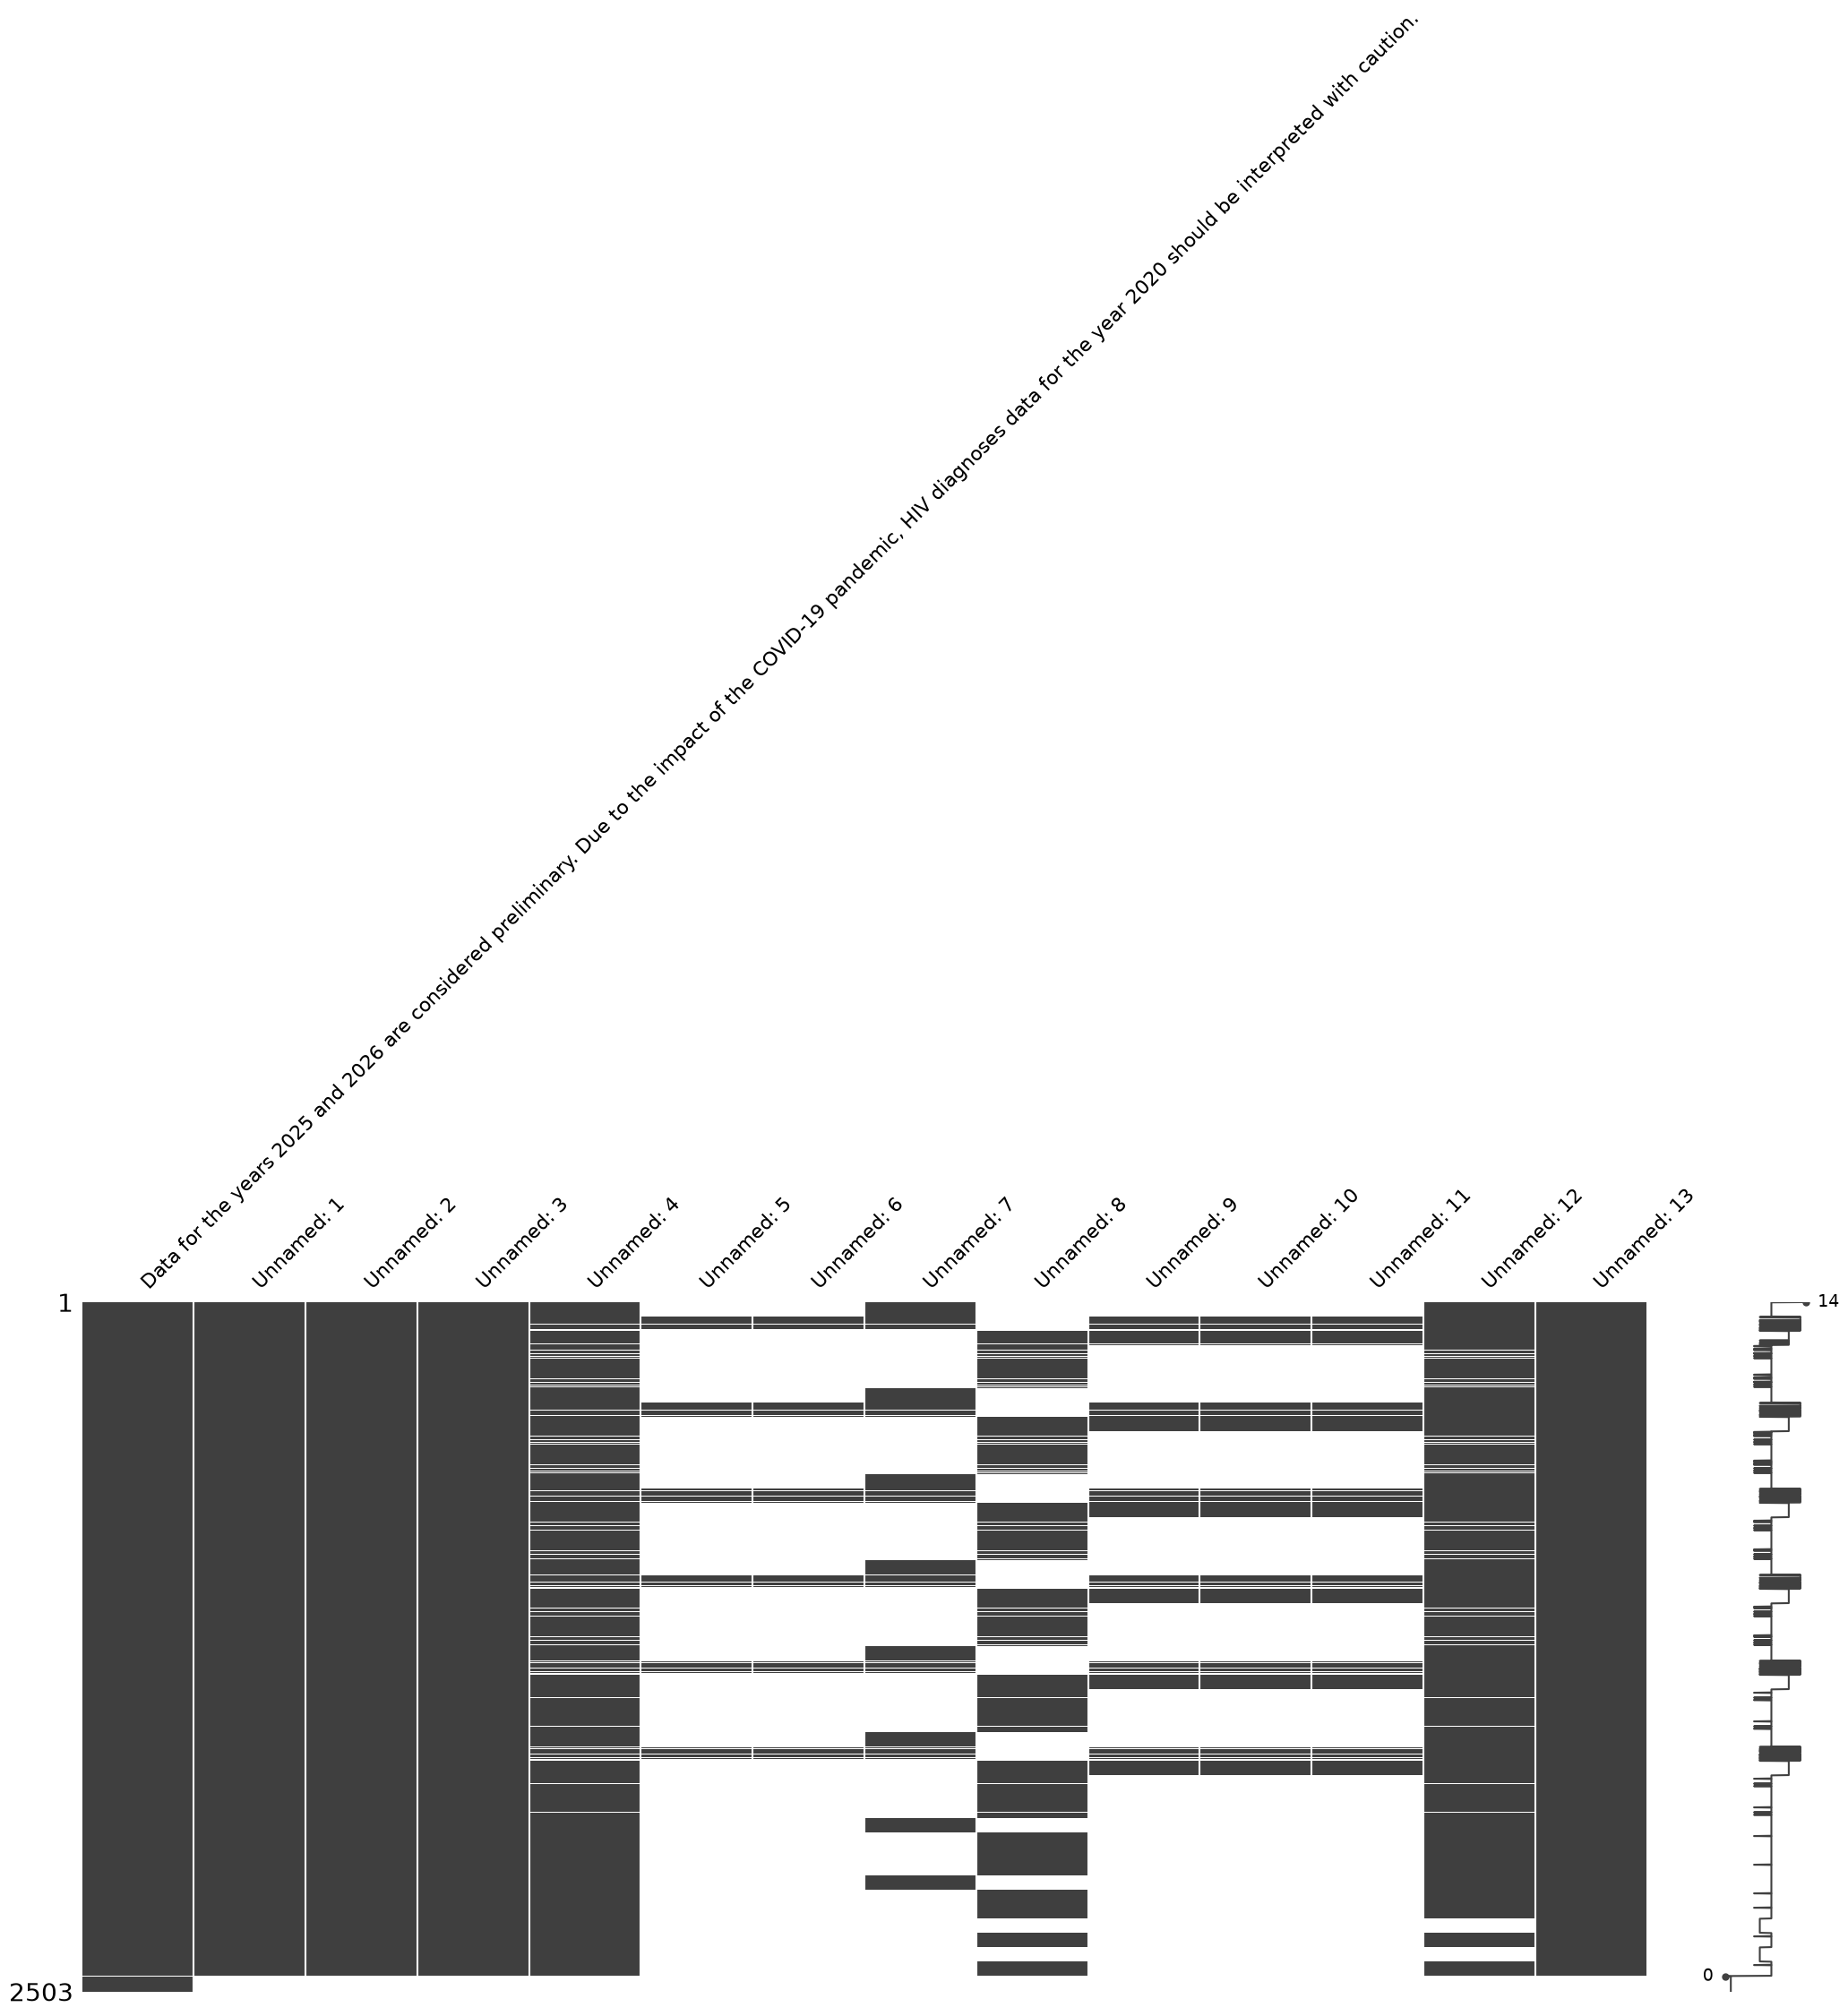

In [4]:
AHEAD_data_state_totals = pd.read_excel("AHEAD_data_all_latest.xlsx", sheet_name="State totals")
msno.matrix(AHEAD_data_state_totals)
plt.show()

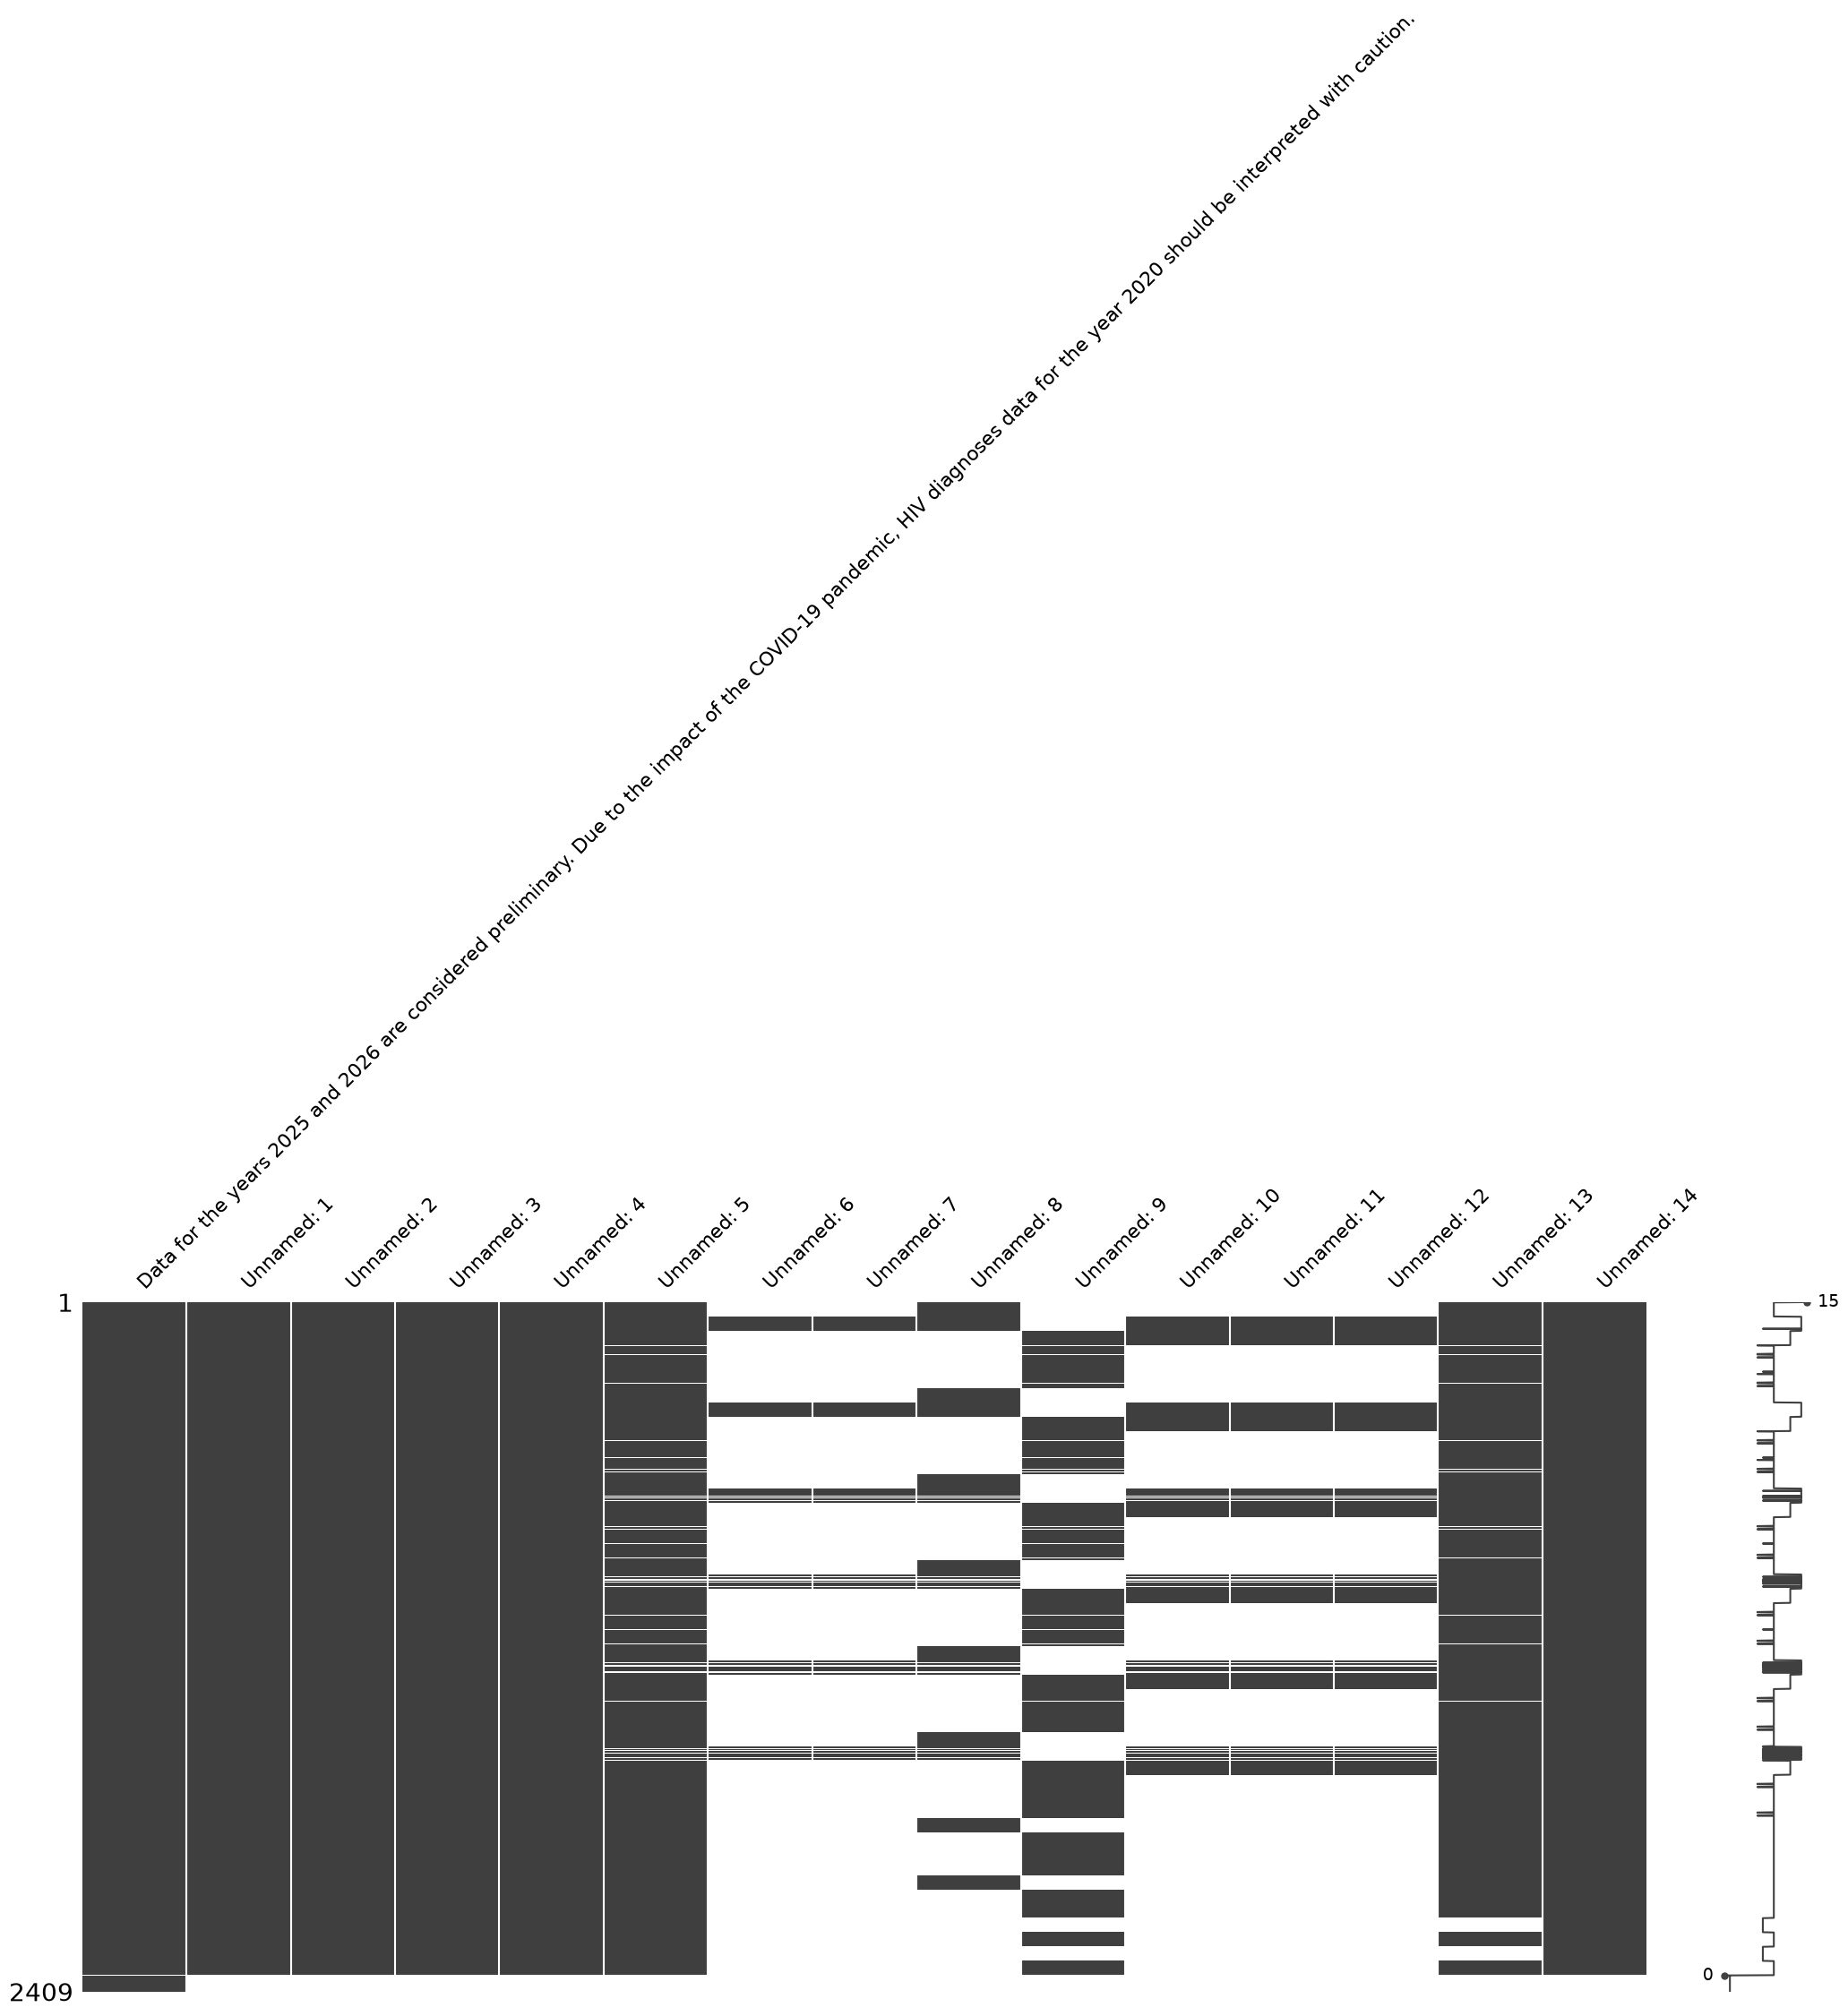

In [5]:
AHEAD_data_jurisdiction_totals = pd.read_excel("AHEAD_data_all_latest.xlsx", sheet_name="Jurisdiction totals")
msno.matrix(AHEAD_data_jurisdiction_totals)
plt.show()

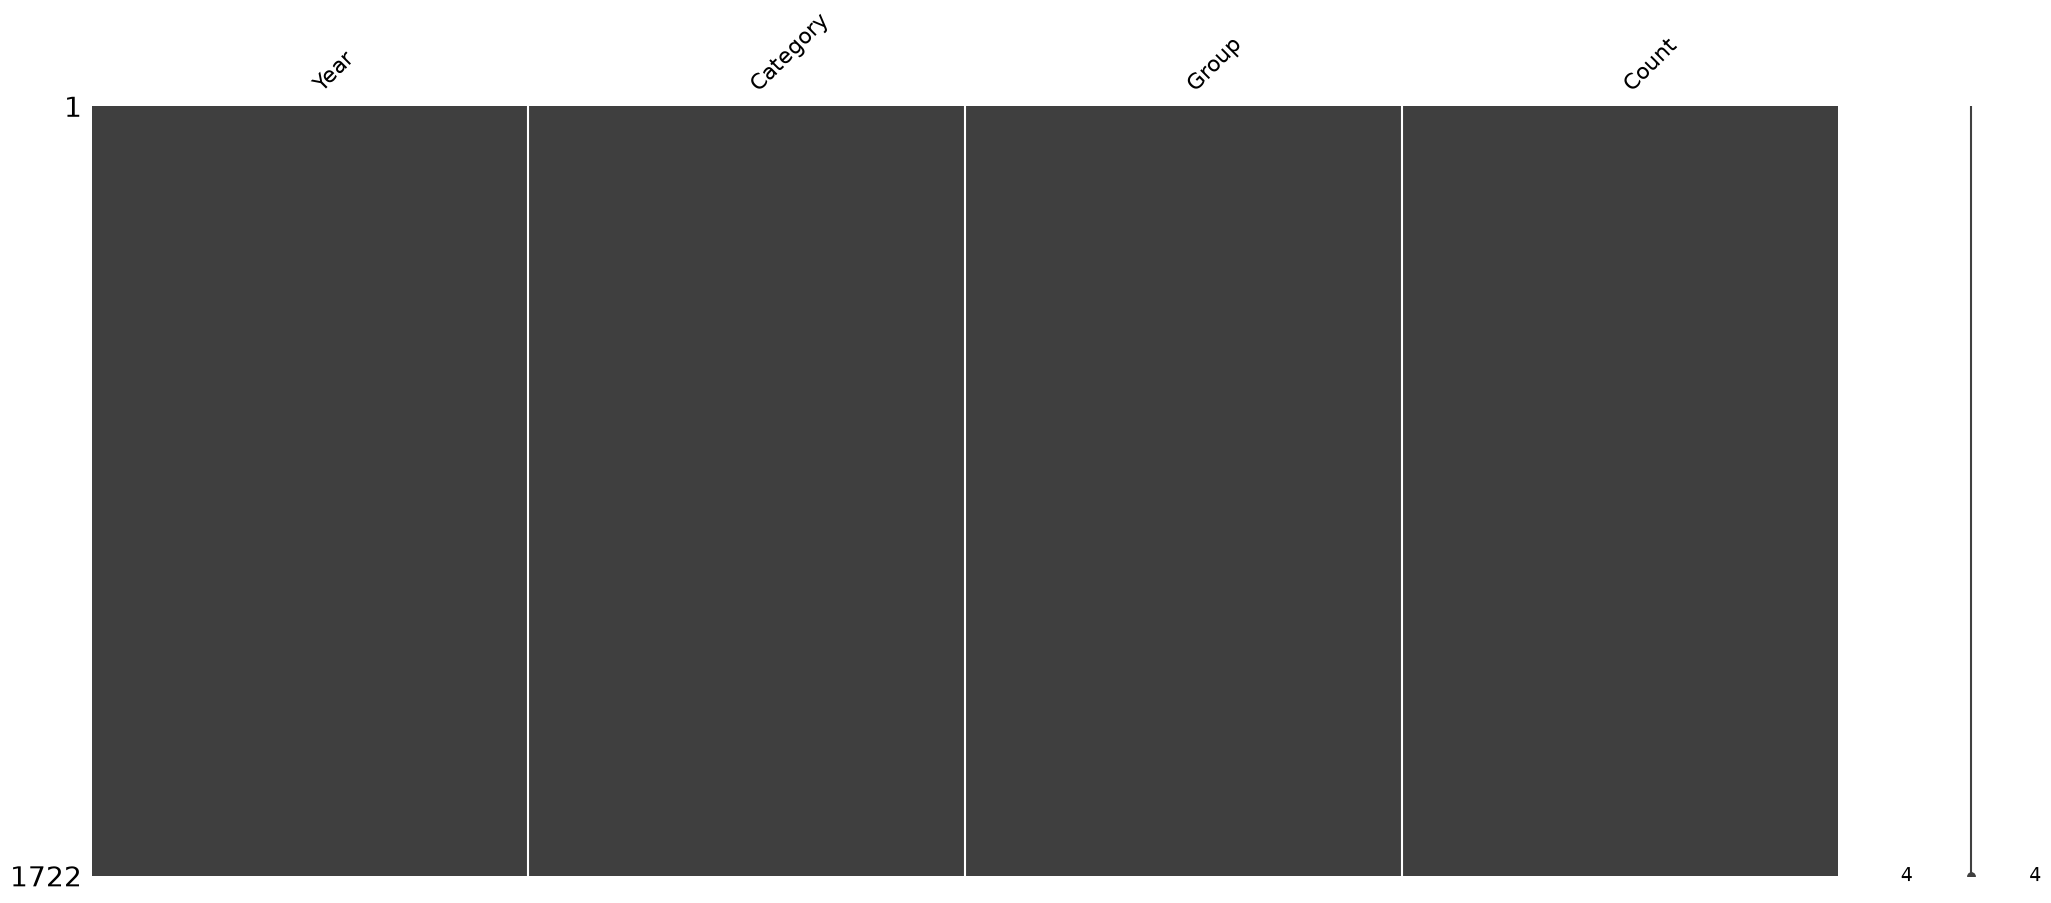

In [6]:
persons_newly_diagnosed_with_hiv = pd.read_csv("persons-newly-diagnosed-with-hiv.csv")
msno.matrix(persons_newly_diagnosed_with_hiv)
plt.show()

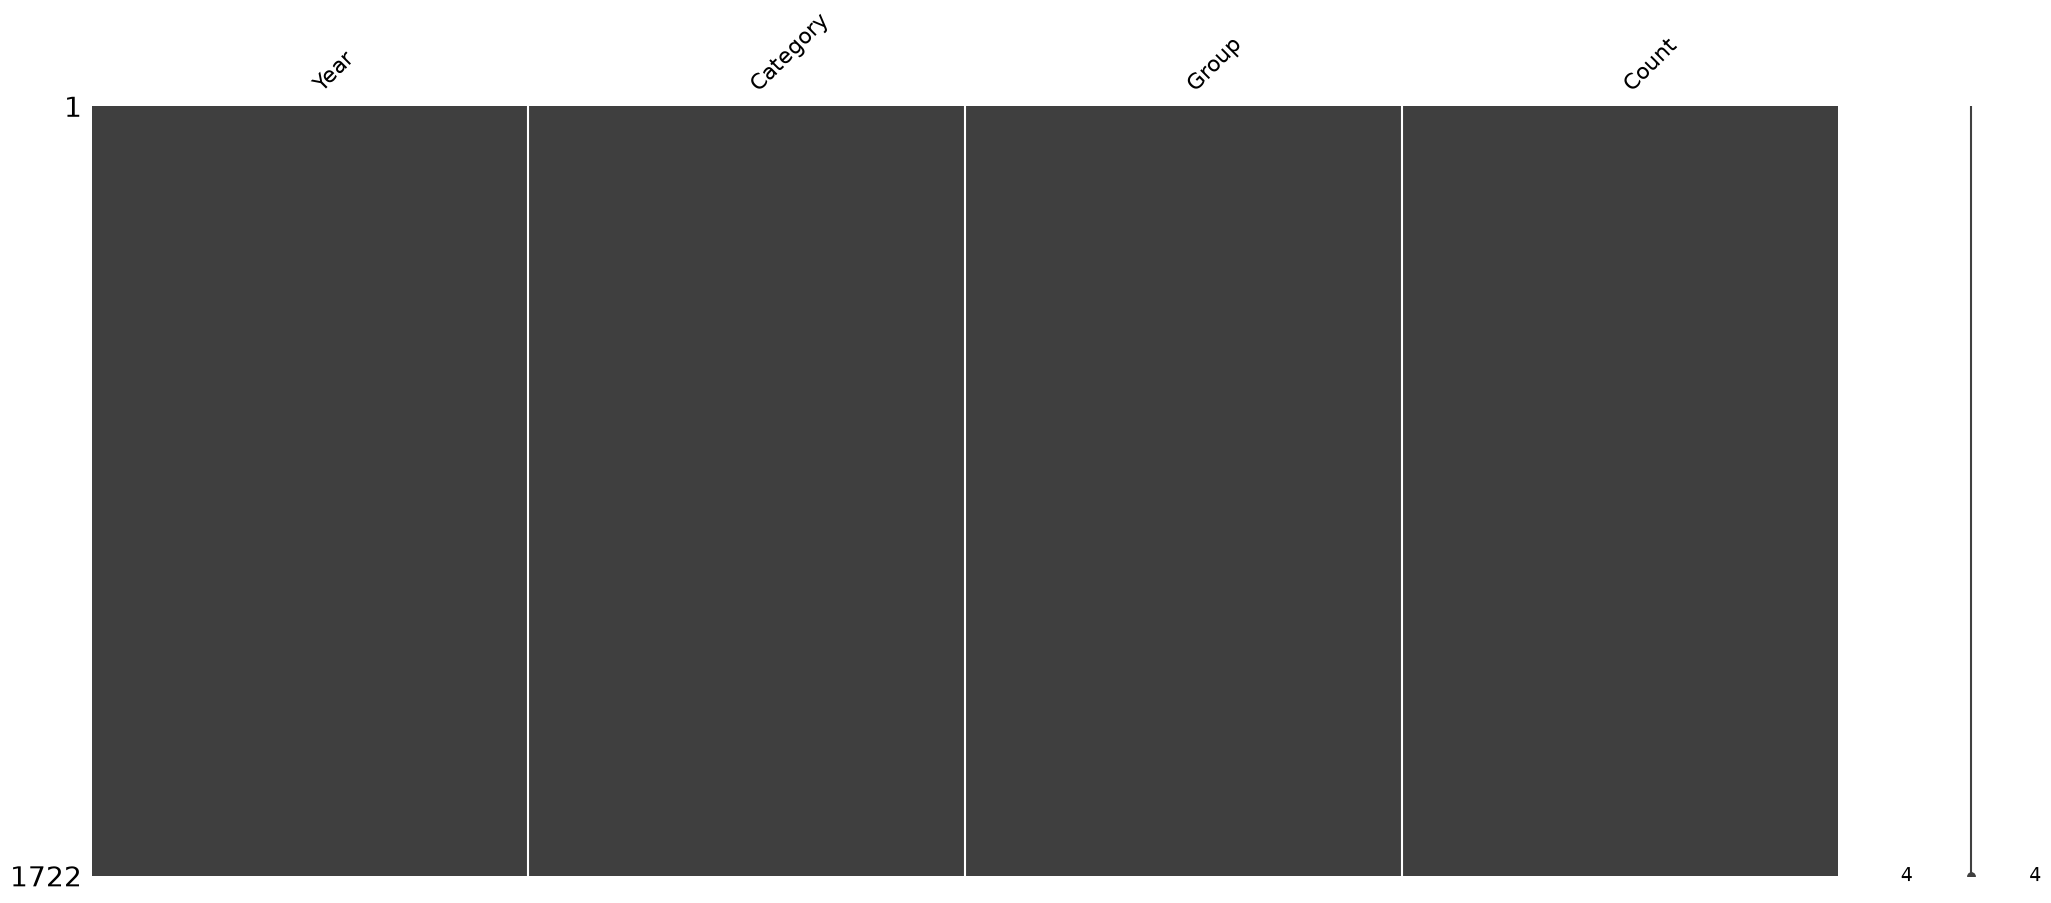

In [7]:
deaths_of_persons_diagnosed_with_hiv_aids = pd.read_csv("deaths-of-persons-diagnosed-with-hiv-aids.csv")
msno.matrix(deaths_of_persons_diagnosed_with_hiv_aids)
plt.show()

In [8]:
df1 = persons_living_with_hiv_aids.rename(columns={'Count': 'Count_Living'})
df2 = persons_newly_diagnosed_with_hiv.rename(columns={'Count': 'Count_New'})
df3 = deaths_of_persons_diagnosed_with_hiv_aids.rename(columns={'Count': 'Count_Deaths'})

combined = (
    df1
    .merge(df2, on=['Year', 'Category', 'Group'])
    .merge(df3, on=['Year', 'Category', 'Group'])
)

combined.head(10)

,Year,Category,Group,Count_Living,Count_New,Count_Deaths
0,2010,Current Gender,Cisgender men,99954,4610,1414
1,2010,Current Gender,Cisgender women,13828,653,238
2,2010,Current Gender,Trans women,1787,93,19
3,2010,Current Gender,Trans men,45,2,0
4,2010,Current Gender,Alternative gender,3,0,0
5,2011,Current Gender,Cisgender men,102658,4438,1471
6,2011,Current Gender,Cisgender women,14110,565,239
7,2011,Current Gender,Trans women,1864,94,22
8,2011,Current Gender,Trans men,46,2,1
9,2011,Current Gender,Alternative gender,4,1,0


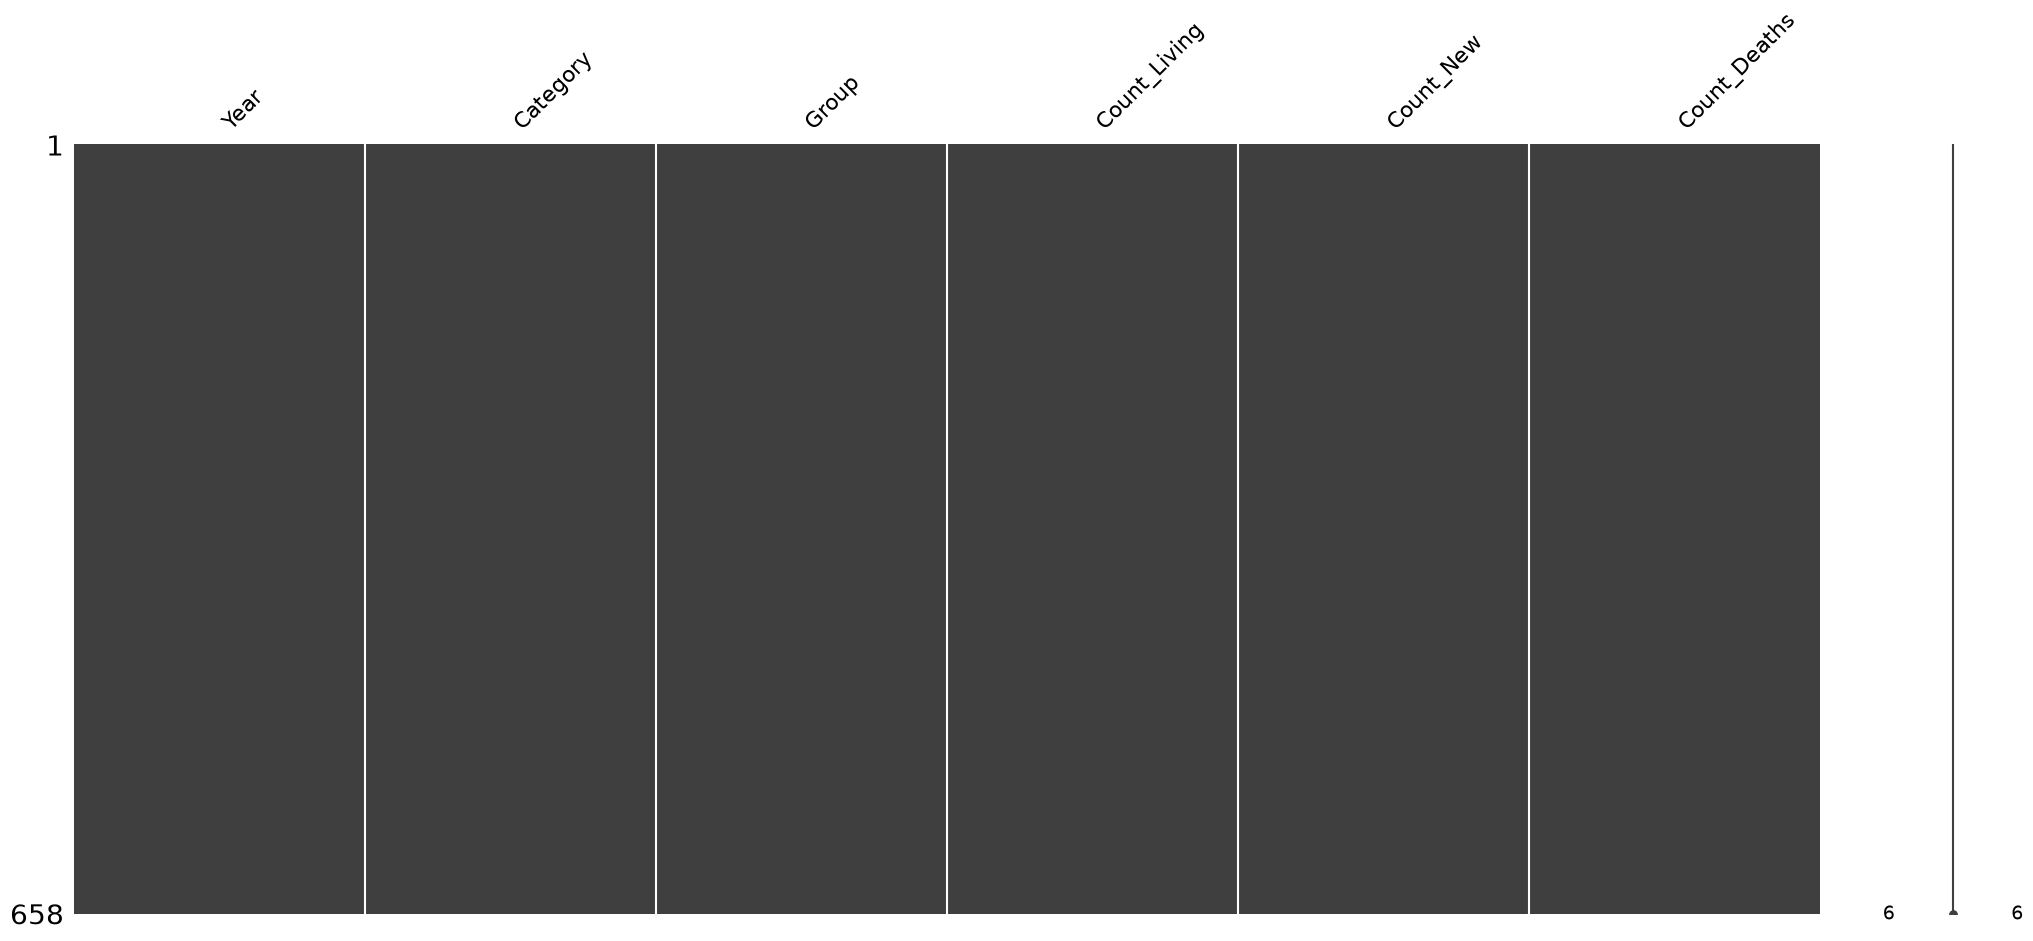

In [9]:
msno.matrix(combined)
plt.show()

In [13]:
measure_cols = ['Count_Living', 'Count_New', "Count_Deaths"]
grp_by = combined.groupby(['Year', 'Category'])[measure_cols].mean()

print(grp_by)

                                                         Count_Living  \
Year Category                                                           
2010 Current Gender                                      23123.400000   
     Race/Ethnicity                                      14452.125000   
     Sex at Birth                                        57808.500000   
     Transmission Category: Alternative Gender Adult...      0.600000   
     Transmission Category: Child (<12 Years Old at ...     58.000000   
...                                                               ...   
2023 Transmission Category: Child (<12 Years Old at ...     21.000000   
     Transmission Category: Cisgender Men Adult or A...  15376.250000   
     Transmission Category: Cisgender Women Adult or...   2843.166667   
     Transmission Category: Trans Men Adult or Adole...     22.400000   
     Transmission Category: Trans Women Adult or Ado...    590.400000   

                                                  